# Choosing a learner per variable

EBM (Explainable Boosting Machine, from InterpretML) fits the same kind of learner on every column — boosted stumps — and adds a
bounded number of pairwise interactions. It returns a fitted shape for each feature and uses the same learner form
across columns.

mboostrs has no fixed learner. `bols` is a straight line, `bbs` a P-spline (a smooth curve in one column),
`btree` a stump (a tree with one split), `brandom` a random effect, `bspatial` a surface, and a formula
can carry a different one per column, or several for the same column with the
selection step choosing between them at every iteration.

[](library_comparison.ipynb) gave every column a `bbs`, as a common specification across datasets. This study compares that choice
with per-column learner choices made through `mboostrs.terms` — see
[](../usage/choosing_terms.ipynb) for the API itself.

This page compares linear, smooth and threshold learners for the same
variables on a shared prediction task. The final comparison separates the effect of
learner choice from the size of the tuning search.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | choosing which learner each variable gets, against fitting one kind everywhere |
| **Observed response** | varies across the compared configurations |
| **Estimand** | held-out predictive risk for each specification |
| **Units** | the risk is on the response's own scale in each configuration |
| **Sampling unit** | one row of the dataset under comparison |
| **Dependence** | treated as independent within each dataset |
| **Split / resampling unit** | the row |
| **Tuning** | each configuration tuned on the same folds, so the comparison is like for like |
| **Uncertainty** | across-fold spread of the held-out risk |
| **Claim type** | predictive comparison between specifications |
:::


In [1]:
import json
from pathlib import Path

import numpy as np
import polars as pl
import altair as alt

import mboostrs as mb

choice = json.loads(Path("bench_term_choice.json").read_text())
runs = pl.DataFrame(choice["results"])
libraries = pl.DataFrame(
    json.loads(Path("bench_libraries_clipped.json").read_text())["results"])

SPECS = ["bbs", "suggested", "trees", "menu", "menu + tree pairs"]
print(f"{runs.height} runs, {runs.filter(pl.col('score').is_null()).height} failed, "
      f"{runs.filter(pl.col('diverged')).height} with a rising training risk")

90 runs, 0 failed, 0 with a rising training risk


## Five specifications

Each specification differs only in which learner goes on which column. The
protocol is the one used throughout: six datasets capped at 5000 rows, three
75/25 splits, twelve tuning configurations scored by three-fold inner
cross-validation, predictions clipped to the training response range.

In [2]:
import sys
sys.path.insert(0, str(Path("../../../benches").resolve()))
import bench_libraries as bench

_, X_elec, _ = bench.encoded_datasets()["electricity"]
elec = {f"f{j}": X_elec[:, j] for j in range(X_elec.shape[1])}

rows = []
for spec, smooth in (("bbs", None), ("suggested", "bbs"),
                     ("trees", "btree"), ("menu", "menu")):
    if smooth is None:
        term = "bbs(f0, df=4) on every column"
    else:
        kinds = {c.name: c for c in mb.classify_columns(elec, smooth=smooth)}
        term = f"f0 -> {kinds['f0'].term}   |   f8 -> {kinds['f8'].term}"
    rows.append({"specification": spec, "electricity, two example columns": term})
display(pl.DataFrame(rows))
print("electricity columns by kind: " + ", ".join(
    f"{k}={v}" for k, v in
    pl.DataFrame([{"kind": c.kind} for c in mb.classify_columns(elec)])
      ["kind"].value_counts().iter_rows()))

specification,"electricity, two example columns"
str,str
"""bbs""","""bbs(f0, df=4) on every column"""
"""suggested""","""f0 -> bbs(f0, df=4.0) | f8…"
"""trees""","""f0 -> btree(f0) | f8 -> bo…"
"""menu""","""f0 -> bols(f0) + bbs(f0, df=4.…"


electricity columns by kind: continuous=7, binary=7


`bbs` puts a P-spline on everything, including the seven two-valued columns
where only a contrast between the two values is needed. `suggested` gives those `bols`. `trees`
puts a stump on the continuous columns instead of a spline. `menu` offers
`bols`, `bbs` and `btree` for each continuous column and lets the selection step
decide. `menu + tree pairs` adds a two-variable `btree` for each pair that survives the residual screen (a check of which column pairs leave structure in the residuals of the additive model).

## Held-out scores by specification

In [3]:
reference = (libraries.group_by("dataset", "library").agg(pl.col("score").mean())
             .group_by("dataset").agg(
                 pl.col("score").filter(pl.col("library") == "EBM").first().alias("EBM"),
                 pl.col("score").filter(pl.col("library")
                       .is_in(["XGBoost", "LightGBM", "CatBoost"])).max().alias("best GBDT")))
scores = (runs.group_by("dataset", "spec").agg(pl.col("score").mean())
          .pivot(on="spec", index="dataset", values="score")
          .join(reference, on="dataset"))
display(scores.select(["dataset"] + SPECS + ["EBM", "best GBDT"])
        .with_columns(pl.exclude("dataset").round(4)))

dataset,bbs,suggested,trees,menu,menu + tree pairs,EBM,best GBDT
str,f64,f64,f64,f64,f64,f64,f64
"""california""",0.7131,0.7131,0.7475,0.7496,0.7986,0.8084,0.8278
"""credit_g""",0.7893,0.7928,0.7816,0.7869,0.7516,0.7955,0.7932
"""electricity""",0.8603,0.8603,0.8897,0.8898,0.9084,0.9085,0.9185
"""breast_cancer""",0.9952,0.9952,0.9965,0.9968,0.9863,0.9985,0.998
"""cpu_act""",0.9805,0.9805,0.9837,0.9844,0.9841,0.9847,0.9853
"""diabetes""",0.4935,0.4935,0.4696,0.474,0.4468,0.4846,0.4471


In [4]:
display(scores.with_columns(
    (pl.col("menu") - pl.col("bbs")).alias("term choice is worth"),
    (pl.col("menu + tree pairs") - pl.col("menu")).alias("interactions are worth"),
    (pl.col("EBM") - pl.max_horizontal(SPECS)).alias("best spec still behind EBM"))
    .select("dataset", "term choice is worth", "interactions are worth",
            "best spec still behind EBM")
    .with_columns(pl.exclude("dataset").round(4))
    .sort("term choice is worth", descending=True))

dataset,term choice is worth,interactions are worth,best spec still behind EBM
str,f64,f64,f64
"""california""",0.0365,0.049,0.0098
"""electricity""",0.0294,0.0187,0.0
"""cpu_act""",0.0038,-0.0003,0.0003
"""breast_cancer""",0.0016,-0.0105,0.0017
"""credit_g""",-0.0024,-0.0353,0.0027
"""diabetes""",-0.0195,-0.0272,-0.0089


Learner choice changes held-out error substantially in two datasets. Moving
from a P-spline on every column to a menu improves held-out score by 0.036 on
california and 0.029 on electricity — about what adding every two-way tensor interaction (a surface over each pair of columns) bought there (0.040 on california, in
[](library_comparison_interactions.ipynb)), for about a thirtieth of the time:
11.4 seconds against 380.6.

On diabetes the menu's held-out score is 0.019 lower. With 331 training rows,
offering three learners per column gives the selection step more
ways to fit noise, and the plain P-spline is the better model. On credit_g,
whose columns are mostly indicators, `suggested` is the best of the five —
correctly declining to smooth what cannot be smoothed — and every richer
specification is worse.

Interactions on top of the menu help california (+0.049) and electricity
(+0.019) and cost credit_g (−0.035), diabetes (−0.027) and breast_cancer
(−0.011); on cpu_act they change nothing (−0.0003). The datasets that lose are
the three smallest.

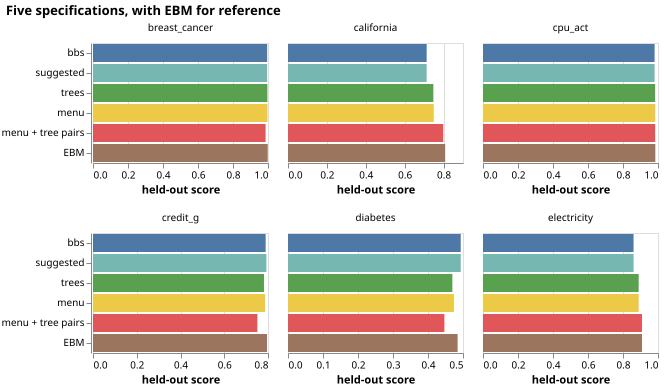

In [5]:
long = pl.concat([
    runs.group_by("dataset", "spec").agg(pl.col("score").mean()),
    reference.select("dataset", pl.lit("EBM").alias("spec"),
                     pl.col("EBM").alias("score"))])
order = SPECS + ["EBM"]
alt.Chart(long).mark_bar().encode(
    y=alt.Y("spec:N", sort=order, title=None),
    x=alt.X("score:Q", title="held-out score", scale=alt.Scale(zero=False)),
    color=alt.Color("spec:N", legend=None, scale=alt.Scale(domain=order,
        range=["#4e79a7", "#76b7b2", "#59a14f", "#edc948", "#e15759", "#9c755f"])),
).properties(width=175, height=120).facet(
    facet=alt.Facet("dataset:N", title=None), columns=3, spacing=16
).resolve_scale(x="independent").properties(
    title="Five specifications, with EBM for reference")

## Comparison with EBM

On diabetes the best specification is ahead of EBM, 0.4935 against 0.4846,
and the best-scoring specification is the plainest one. On cpu_act (0.9844 against
0.9847) and electricity (0.9084 against 0.9085) it is within 0.0003. On the
other three EBM is still ahead, by 0.0017 on breast_cancer, 0.0024 on credit_g
and 0.0098 on california.

The best learner specification exceeds EBM on one of six datasets and comes
within 0.0003 on two more. These results compare the tested specifications and
tuning grids on the shared splits.

## Effect of the tuning search

The tuning grid chooses `mstop` (the number of boosting steps), `nu` (the step length) and tree depth by inner cross-validation
over twelve configurations.

Fixing `mstop=4000` and `maxdepth=4` by hand, rather than letting the inner
cross-validation pick, and averaging over the same three splits gives the
fixed-setting columns below. They were measured separately from the tuned runs, at the fixed settings stated here; the tuned column is the `menu + tree pairs` score from the table above:

In [6]:
display(pl.DataFrame([
    {"dataset": "electricity", "tuned by inner CV": 0.9084,
     "mstop=4000, depth=4, screened pairs": 0.9084,
     "mstop=4000, depth=4, every pair": 0.9119, "EBM": 0.9085},
    {"dataset": "california", "tuned by inner CV": 0.7986,
     "mstop=4000, depth=4, screened pairs": 0.7794,
     "mstop=4000, depth=4, every pair": 0.7902, "EBM": 0.8084},
]))

dataset,tuned by inner CV,"mstop=4000, depth=4, screened pairs","mstop=4000, depth=4, every pair",EBM
str,f64,f64,f64,f64
"""electricity""",0.9084,0.9084,0.9119,0.9085
"""california""",0.7986,0.7794,0.7902,0.8084


On electricity the tuned score equals the fixed screened-pairs setting
(0.9084) and is 0.0035 below the fixed every-pair setting (0.9119); on
california the tuned score (0.7986) is above both fixed settings. On these two
datasets the inner cross-validation finds a setting as good as the hand-fixed
ones. Twelve configurations over a four-dimensional grid is a thin search. The result is also sensitive to implementation details: under a different implementation with the same seeds, the tuned electricity score was 0.8911, 0.017 lower than the 0.9084 reported here.

A single split can give a misleading score. One electricity setting scores 0.9307 on a single split but averages 0.9119 over three splits, with individual scores of 0.9300, 0.9057 and 0.9000. The comparison in this page therefore uses averages over three splits.

## Conclusions

The `suggested` specification is the fastest of the five at 2.5 seconds.
It avoids fitting splines to indicator columns, which reduces computation time.

The richer specifications improve scores on some larger datasets and worsen
them on the smaller datasets in this comparison. `menu + tree pairs`
costs 38.4 seconds against 3.2 for `bbs`, and buys 0.049 on california and
0.019 on electricity at the price of −0.027 on diabetes and −0.035 on credit_g. The richer candidate menu therefore does not improve every task.

EBM and mboostrs each lead on some datasets. Within this comparison, changing
the mboostrs terms can alter its score more than the gap between its best
specification and EBM.

In [7]:
display(runs.group_by("spec").agg(
    pl.col("total_seconds").mean().alias("seconds to tune and refit"))
    .with_columns(pl.col("seconds to tune and refit").round(1))
    .sort("seconds to tune and refit"))

spec,seconds to tune and refit
str,f64
"""suggested""",2.5
"""bbs""",3.2
"""trees""",5.7
"""menu""",11.4
"""menu + tree pairs""",38.4
